---
title: "M2HATS ISS 449 MHz wind profiler: daily time-height curtains"
author: Jacquelyn Witte
date: 2026-11-18
---

# Daily time-height curtains from the M2HATS 449 MHz wind profiler

[M2HATS](https://www.eol.ucar.edu/field_projects/m2hats) was a 2023 field campaign in which the
NSF NCAR Earth Observing Laboratory (EOL) deployed its **Integrated Sounding System (ISS)**.
One ISS instrument is a **radar wind profiler**: a vertically pointing radar that measures
echoes from turbulence in clear air. From the strength and Doppler shift of those echoes it
derives vertical motion and horizontal wind at a range of heights above the site, many times
an hour.

GDEX serves the 449 MHz profiler record as [dataset d361534](https://gdex.ucar.edu/datasets/d361534/).
It has **one Zarr store per day**, each with three groups, one per data product:

| Group | What it holds |
|---|---|
| `moments` | Per-dwell Doppler moments, including signal-to-noise ratio (`sigNoiseRatio`) and vertical velocity (`vel`) |
| `winds_5min` | Consensus horizontal winds averaged over 5 minutes |
| `winds_30min` | Consensus horizontal winds averaged over 30 minutes |

This notebook opens one day and draws a three-panel **curtain plot**: time on the x-axis,
height on the y-axis, colored by

1. **Signal-to-noise ratio** (dB), which shows where the radar has a usable return,
2. **Vertical velocity** (m/s), which shows updrafts and downdrafts,
3. **Wind speed** (m/s), overlaid with wind barbs showing direction.

:::{note} New to Zarr?
Each daily store is in [Zarr format](../docs/zarr_format.md). Opening a group with
`xr.open_zarr()` returns an ordinary `xarray.Dataset`, so everything after that works
the same as with NetCDF.
:::

:::{seealso} How to cite these data
NSF/NCAR EOL Integrated Sounding System Team. 2026. *M2HATS: ISS Radar 449 MHz Wind Profiler Data.*
NSF National Center for Atmospheric Research. https://gdex.ucar.edu/datasets/d361534/. Accessed dd mmm yyyy.

EOL also asks you to cite the source data:
[doi:10.26023/ZH7Z-GRWB-AV0F](https://doi.org/10.26023/ZH7Z-GRWB-AV0F).
:::

[![Binder](https://binder.k8s.ucar.edu/badge_logo.svg)](https://binder.k8s.ucar.edu/v2/gh/NCAR/gdex-examples/main?labpath=notebooks/eol_m2hats_prof449.ipynb)

*Run this notebook interactively on CIRRUS BinderHub.*

In [1]:
import os
import re
from glob import glob
from urllib.parse import urljoin

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import requests
import xarray as xr

## Find the daily zarr stores

:::{important} No edits needed
The cells below **automatically select the data path** — POSIX where `/gdex/data` is
mounted (NCAR HPC, CIRRUS Binder), otherwise OSDF over the network. **You don't
need to change anything.**
:::

In [2]:
DSID = "d361534"   # GDEX dataset ID: M2HATS ISS 449 MHz wind profiler

posix_dir = f"/gdex/data/{DSID}/zarr/"
osdf_dir  = f"https://osdf-director.osg-htc.org/ncar/gdex/{DSID}/zarr/"


def list_https_stores(base_url):
    """Return the URLs of the .zarr stores in an HTTPS directory listing."""
    r = requests.get(base_url, timeout=60)
    r.raise_for_status()
    return sorted(urljoin(base_url, h) for h in re.findall(r'href="([^"?]+\.zarr/?)', r.text))

In [3]:
# Use POSIX access when the archive is mounted, otherwise OSDF
if os.path.isdir(posix_dir):
    BASE   = posix_dir
    stores = sorted(glob(os.path.join(posix_dir, "*.zarr")))
else:
    BASE   = osdf_dir
    stores = list_https_stores(osdf_dir)

if not stores:
    raise ValueError(f"No Zarr stores found under {BASE}")

names = [os.path.basename(s.rstrip("/")) for s in stores]
print(f"Access: {'POSIX mount' if BASE == posix_dir else 'OSDF (remote)'}")
print(f"Found {len(stores)} daily stores: {names[0]} … {names[-1]}")

Access: POSIX mount
Found 79 daily stores: m2hats_eol-iss_windradar_449MHz_20230711_v1.zarr … m2hats_eol-iss_windradar_449MHz_20230927_v1.zarr


## 1. Configuration

#### Settings to edit
Edit the values below before running. 
'WINDS_RESOLUTION` selects whether to use the 5-minute or 30-minute averaged winds for panel 3.

In [5]:
# Settings to edit
DATE             = "20230909"   # YYYYMMDD; must be within the range printed above
WINDS_RESOLUTION = "30min"      # winds for panel 3: "5min" or "30min"
CAMPAIGN         = "M2HATS"
MAX_HEIGHT       = 6000         # top of the plot, m MSL

# Daily store for the chosen date
store_name = f"{CAMPAIGN.lower()}_eol-iss_windradar_449MHz_{DATE}_v1.zarr"
if store_name not in names:
    raise ValueError(f"No store for {DATE}. Choose a date from {names[0]} to {names[-1]}.")
ZARR_STORE = f"{BASE}{store_name}"

# Color limits
SNR_VMIN,  SNR_VMAX,  SNR_CMAP  = -15.0, 15.0, "plasma"    # panel 1: signal-to-noise ratio, dB
VEL_VMIN,  VEL_VMAX,  VEL_CMAP  =  -2.0,  2.0, "RdBu_r"    # panel 2: vertical velocity, m/s
WSPD_VMIN, WSPD_VMAX, WSPD_CMAP =   0.0, 15.0, "viridis"   # panel 3: wind speed, m/s

# Output
SAVE_FIGURE = False   # True saves a PNG to OUTPUT_DIR; False only displays it
OUTPUT_DIR  = "."

## 2. Opening the Zarr store

The daily store contains three groups:
- `moments` — high-rate Doppler data (one time step per radar dwell)
- `winds_5min` or `winds_30min` — time-averaged consensus winds

`consolidated=True` reads the single `.zmetadata` summary file at the store root
rather than opening each variable's metadata file one by one — faster, especially
over a networked filesystem. 

The `height` coordinate is 2-D `(time, height)` in all groups. Heights are constant
across time for this instrument, so `height[0, :]` gives a representative 1-D
height vector for the y-axis. A `MAX_HEIGHT` mask then trims it to the configured
upper limit before plotting.

In [7]:
# Open both groups — each returns a standard xarray Dataset
ds_mom   = xr.open_zarr(ZARR_STORE, group='moments', consolidated=True)
ds_winds = xr.open_zarr(ZARR_STORE, group=f'winds_{WINDS_RESOLUTION}', consolidated=True)

# Time arrays — xarray CF-decodes to datetime64[ns]
time_mom   = ds_mom['time'].values
time_winds = ds_winds['time'].values

# height is 2-D (time, height) in both groups; use the first row as a representative
# 1-D height vector — heights are constant across time for this instrument
height_mom   = ds_mom['height'].values[0, :]
height_winds = ds_winds['height'].values[0, :]

# Build a boolean mask selecting height levels at or below MAX_HEIGHT
# This is used to slice the 2-D (time, height) arrays before plotting to remove empty space
hi_mom   = height_mom   <= MAX_HEIGHT
hi_winds = height_winds <= MAX_HEIGHT

# Extract the science arrays, applying the height mask along the height axis
snr  = ds_mom['sigNoiseRatio'].values[:, hi_mom]
vel  = ds_mom['vel'].values[:, hi_mom]
wspd = ds_winds['wspd'].values[:, hi_winds]
u    = ds_winds['u'].values[:, hi_winds]
v    = ds_winds['v'].values[:, hi_winds]

## 3. Plotting the curtains

A **curtain plot** stacks time along the x-axis and height along the y-axis,
showing how a variable evolves through the day at each altitude level.
`pcolormesh` draws the filled color grid; wind barbs are overlaid on panel 3
using subsampled `u` and `v` components converted from m/s to knots (the
meteorological convention for barb plots).

Wind barbs are subsampled to ~60 time × 15 height points for readability — the
full-resolution data would produce an unreadable dense grid of barbs. The
`[::t_step]` notation means "take every t_step-th element", so the step size
adapts to however many time or height levels are in the dataset.

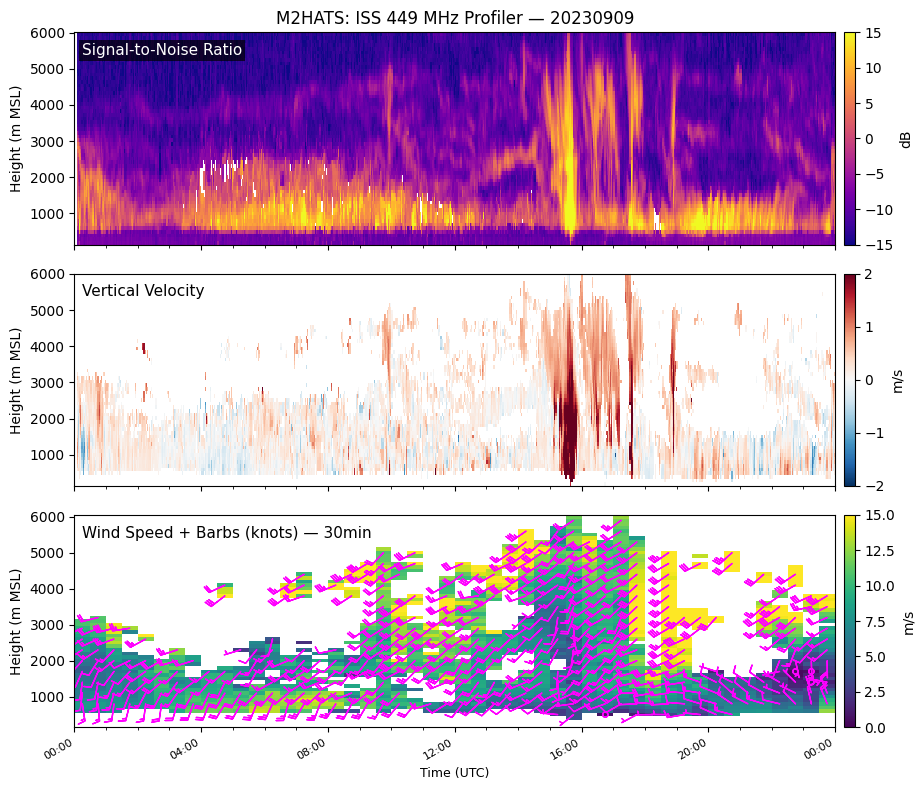

In [8]:
# Wind barb subsampling — target ~60 time × 15 height points regardless of resolution
n_time_winds, n_hgt_winds = u.shape
t_step = max(1, n_time_winds // 60)
h_step = max(1, n_hgt_winds  // 15)

# [::t_step] takes every t_step-th element along that axis
# [::h_step] takes every h_step-th element along that axis
t_sub = time_winds[::t_step]
h_sub = height_winds[:n_hgt_winds][::h_step]
u_sub = u[::t_step, ::h_step]
v_sub = v[::t_step, ::h_step]

# Convert u, v from m/s to knots — meteorological convention for wind barbs
MS_TO_KNOTS = 1.94384
u_kts = u_sub * MS_TO_KNOTS
v_kts = v_sub * MS_TO_KNOTS
# Repeat time and height values across height columns and time rows to create a 2-D grid for wind barb plotting
T_grid, H_grid = np.meshgrid(t_sub, h_sub, indexing='ij')

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.subplots_adjust(hspace=0.06)

# Panel 1: signal-to-noise ratio
# The transpose is important: the snr array is shaped [time, height], 
# but pcolormesh expects [y, x] = [height, time], so .T flips it to align with axes.
pcm1 = ax1.pcolormesh(time_mom, height_mom[hi_mom], snr.T,
                      vmin=SNR_VMIN, vmax=SNR_VMAX, cmap=SNR_CMAP, shading='nearest')
fig.colorbar(pcm1, ax=ax1, label='dB', pad=0.01)
ax1.set_ylabel('Height (m MSL)')
ax1.set_title(f'{CAMPAIGN}: ISS 449 MHz Profiler — {DATE}', fontsize=12)
bbox = dict(facecolor='black', alpha=0.7, pad=2, edgecolor='none')
ax1.text(0.01, 0.95, 'Signal-to-Noise Ratio', transform=ax1.transAxes,
         va='top', fontsize=11, color='white', bbox=bbox)

# Panel 2: vertical velocity
pcm2 = ax2.pcolormesh(time_mom, height_mom[hi_mom], vel.T,
                      vmin=VEL_VMIN, vmax=VEL_VMAX, cmap=VEL_CMAP, shading='nearest')
fig.colorbar(pcm2, ax=ax2, label='m/s', pad=0.01)
ax2.set_ylabel('Height (m MSL)')
ax2.text(0.01, 0.95, 'Vertical Velocity', transform=ax2.transAxes,
         va='top', fontsize=11)

# Panel 3: wind speed background + wind barbs
pcm3 = ax3.pcolormesh(time_winds, height_winds[hi_winds], wspd.T,
                      vmin=WSPD_VMIN, vmax=WSPD_VMAX, cmap=WSPD_CMAP, shading='nearest')
fig.colorbar(pcm3, ax=ax3, label='m/s', pad=0.01)
ax3.barbs(T_grid.flatten(), H_grid.flatten(), u_kts.flatten(), v_kts.flatten(),
          length=5, linewidth=1, color='magenta')
ax3.set_ylabel('Height (m MSL)')
ax3.text(0.01, 0.95, f'Wind Speed + Barbs (knots) — {WINDS_RESOLUTION}',
         transform=ax3.transAxes, va='top', fontsize=11, color='black')

# Shared x-axis formatting applied to bottom panel only
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax3.xaxis.set_major_locator(mdates.HourLocator(interval=4))
ax3.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 60]))
plt.setp(ax3.get_xticklabels(), rotation=30, ha='right', fontsize=8)
ax3.set_xlabel('Time (UTC)', fontsize=9)

fig.tight_layout()

if SAVE_FIGURE:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out_path = os.path.join(OUTPUT_DIR, f'{CAMPAIGN}_prof449_{WINDS_RESOLUTION}_{DATE}_curtain.png')
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f'Saved: {out_path}')
else:
    plt.show()